# Stellar Astrophysics (Academic Year 2025/2026)

#### Lecture for the Master's degree on "Physics of the Universe: Cosmology, Astrophysics, Particles and Astroparticles" at the University of Zaragoza, Spain. <br>

**Lectures:** Maurizio Giannotti <br> 
**Tutorials:** Francisco Rodríguez Candón (francandon@unizar.es) and Mathieu Kaltschmidt (mkaltschmidt@unizar.es)

In [1]:
#Import relevant modules
import matplotlib.pyplot as plt
import numpy as np

#plot setup

plt.rcParams['mathtext.fontset'] = 'cm'
plt.default_fontfam = plt.rcParams['font.family']
plt.rcParams['font.family'] = 'STIXGeneral'

import sys
# sys.path.append("path/to/py_mesa_reader") #modify to your respective path 
import mesa_reader as mr


## Task 1: Simulating the Sun

Use your simulation of the Sun and plot some of the basic quantities such as the temperature profile, the abundunces of H and He (and other elements) and the HR diagram (more advanced).

### 1.1 : History files

Let's first load the history and plot the evolution of some scalar variables over the duration of our simulation

In [2]:
# Loading the history file
h = mr.MesaData("./Sun/LOGS/history.data") 

print("Number of columns:", len(h.bulk_names))
print("Example columns:", h.bulk_names)

Number of columns: 57
Example columns: ('model_number', 'num_zones', 'star_age', 'log_dt', 'star_mass', 'log_xmstar', 'log_abs_mdot', 'mass_conv_core', 'conv_mx1_top', 'conv_mx1_bot', 'conv_mx2_top', 'conv_mx2_bot', 'mx1_top', 'mx1_bot', 'mx2_top', 'mx2_bot', 'log_LH', 'log_LHe', 'log_LZ', 'log_Lnuc', 'pp', 'cno', 'tri_alpha', 'epsnuc_M_1', 'epsnuc_M_2', 'epsnuc_M_3', 'epsnuc_M_4', 'epsnuc_M_5', 'epsnuc_M_6', 'epsnuc_M_7', 'epsnuc_M_8', 'he_core_mass', 'co_core_mass', 'one_core_mass', 'fe_core_mass', 'neutron_rich_core_mass', 'log_Teff', 'log_L', 'log_R', 'log_g', 'v_div_csound_surf', 'log_cntr_P', 'log_cntr_Rho', 'log_cntr_T', 'center_mu', 'center_ye', 'center_abar', 'center_h1', 'center_he4', 'center_c12', 'center_o16', 'surface_c12', 'surface_o16', 'total_mass_h1', 'total_mass_he4', 'num_retries', 'num_iters')


In [3]:
#check if star age matches with your stopping condition
final_age = h.star_age[-1]
print(f"Final star age: {final_age/1e9:.2f} billion years")

Final star age: 12.20 billion years


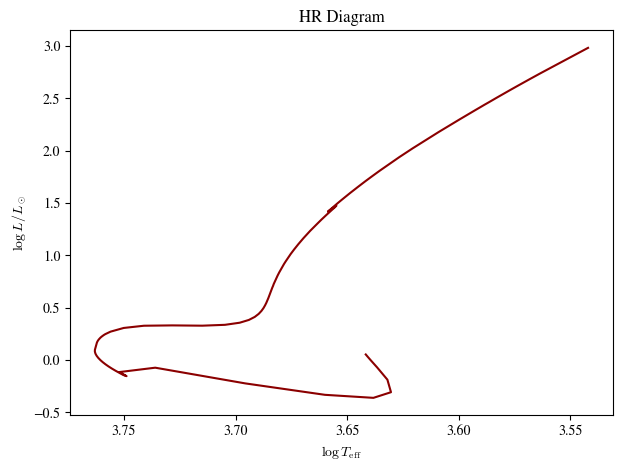

In [4]:
# 1. HR diagram
logTeff = h.log_Teff
logL = h.log_L

plt.figure(figsize=(7,5))
plt.plot(logTeff, logL, color="darkred")
plt.gca().invert_xaxis()
plt.xlabel(r"$\log T_{\rm eff}$")
plt.ylabel(r"$\log L/L_\odot$")
plt.title("HR Diagram")
plt.show()

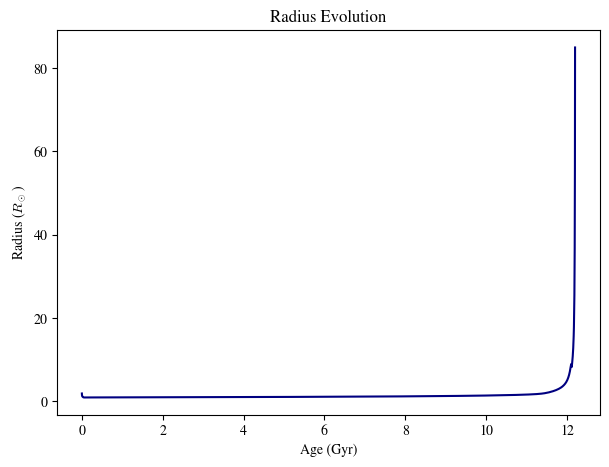

In [5]:
# 2. Radius evolution

logR = h.bulk_data["log_R"]        # log10 of radius in solar units
radius = 10**logR                  # radius in solar radii

ages = h.star_age                 # age in years
plt.figure(figsize=(7,5))
plt.plot(ages/1e9, radius, color="navy")
plt.xlabel("Age (Gyr)")
plt.ylabel("Radius ($R_\\odot$)")
plt.title("Radius Evolution")
plt.show()


### 1.2 : Profile files

Now we are going to learn to open the different profiles that we saved. Profiles are arrays that contains the information of different variables across the radius of the star

In [12]:
logs = mr.MesaLogDir("./Sun/LOGS/")
# For the profiles
index = mr.MesaProfileIndex(file_name='./Sun/LOGS/profiles.index')

p = logs.profile_data(profile_number=6)  # load one profile by its number

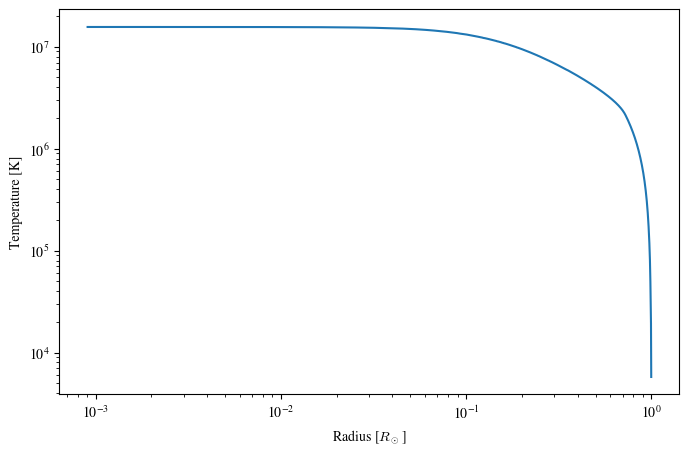

Core Temperature: 15.62 million K
Surface Temperature: 5764.56 K


In [13]:
# 1. Temperature profile

R = p.R     # Solar Radii
T = p.T     # K

log_rho = np.log10(p.Rho)

plt.figure(figsize=(8,5))
plt.loglog(R, p.T)
plt.xlabel("Radius [$R_\\odot$]")
plt.ylabel("Temperature [K]")
plt.show()

# Let's print out the surface temperature and core temperature
print(f"Core Temperature: {T[-1]/1e6:.2f} million K")
print(f"Surface Temperature: {T[0]:.2f} K")

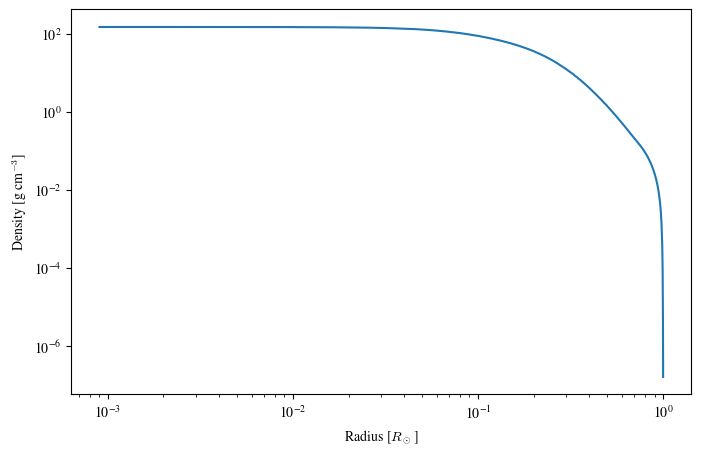

Core Density: 149.01 g cm^-3


In [14]:
# 2. Density profile

log_rho = np.log10(p.Rho)  # log10 of density in g/cm^3
plt.figure(figsize=(8,5))
plt.loglog(R, 10**log_rho)
plt.xlabel("Radius [$R_\\odot$]")
plt.ylabel("Density [g cm$^{-3}$]")
plt.show()
# Let's print out the core density and surface density
print(f"Core Density: {10**log_rho[-1]:.2f} g cm^-3")

In [15]:
p.bulk_names

('zone',
 'mass',
 'logR',
 'logT',
 'logRho',
 'logP',
 'x_mass_fraction_H',
 'y_mass_fraction_He',
 'z_mass_fraction_metals',
 'dm',
 'eps_grav',
 'eps_nuc',
 'non_nuc_neu',
 'pp',
 'cno',
 'tri_alpha',
 'h1',
 'he3',
 'he4',
 'c12',
 'n14',
 'o16',
 'ne20',
 'mg24')

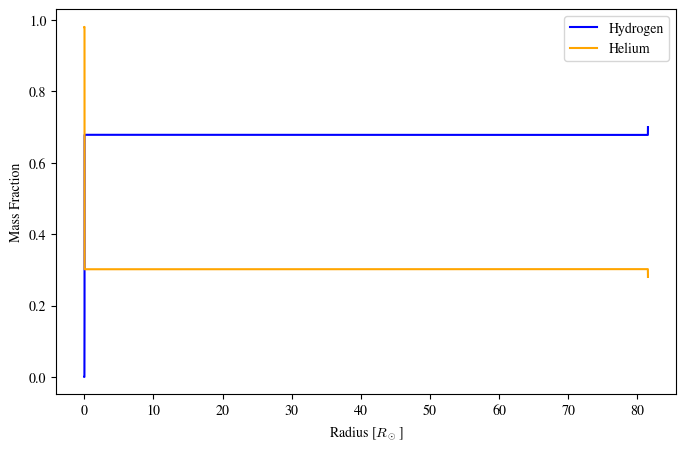

In [10]:
# 3. Hydrogen and Helium profiles abundance
X_H = p.x_mass_fraction_H     # Hydrogen mass fraction
X_He = p.y_mass_fraction_He    # Helium mass fraction
plt.figure(figsize=(8,5))
plt.plot(R, X_H, label="Hydrogen", color="blue")
plt.plot(R, X_He, label="Helium", color="orange")
plt.xlabel("Radius [$R_\\odot$]")
plt.ylabel("Mass Fraction")
plt.legend()
plt.show()

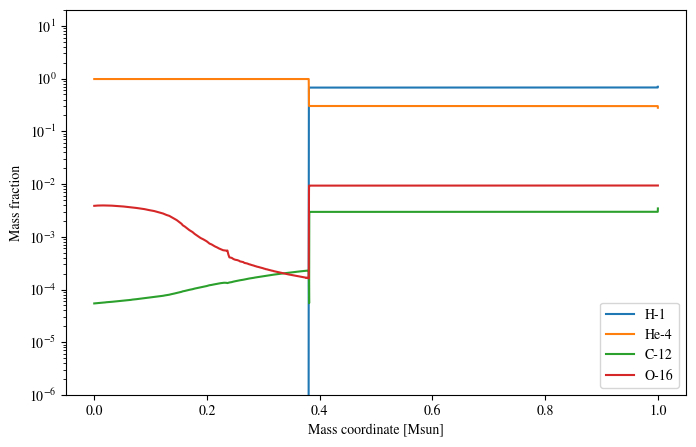

In [11]:
plt.figure(figsize=(8,5))
plt.plot(p.mass, p.h1, label="H-1")
plt.plot(p.mass, p.he4, label="He-4")
plt.plot(p.mass, p.c12, label="C-12")
plt.plot(p.mass, p.o16, label="O-16")
plt.legend()
plt.xlabel("Mass coordinate [Msun]")
plt.ylabel("Mass fraction")
plt.ylim(1e-6,20)
plt.yscale("log")